# Εργασία 3 – Αξιολόγηση Μοντέλων

# Μέρος 1

# Φόρτωση Βιβλιοθηκών

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_validate, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    mean_absolute_error, mean_squared_error
)
from scipy.stats import t

In [2]:
df = pd.read_csv('sleep.csv')

# Έλεγχος δεδομένων στο dataset

In [3]:
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


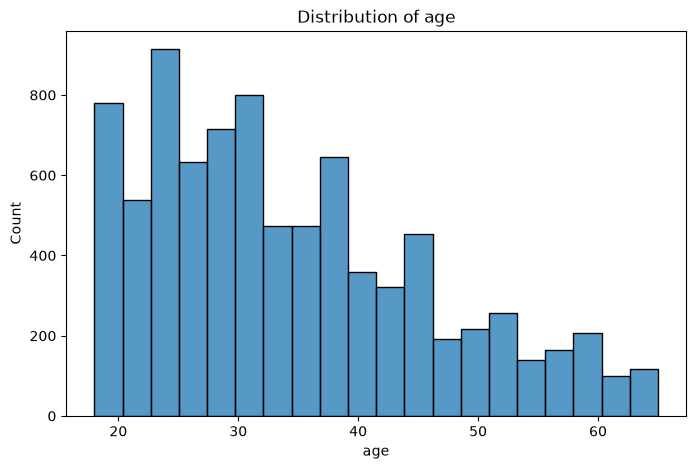

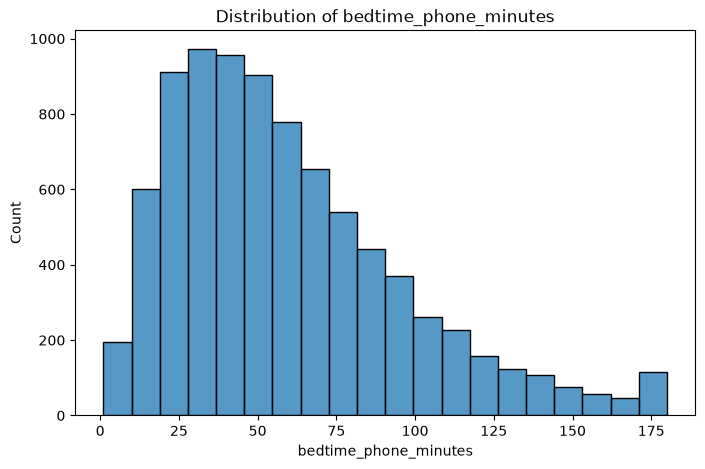

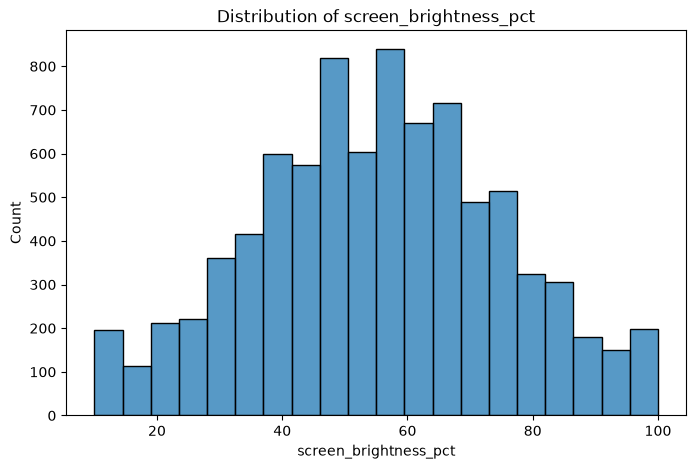

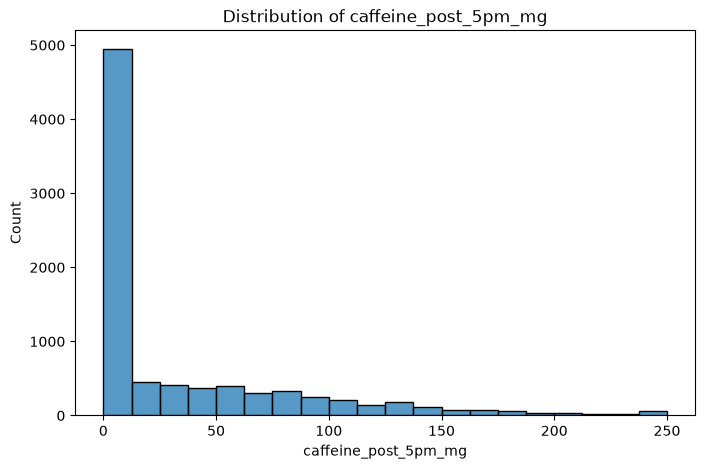

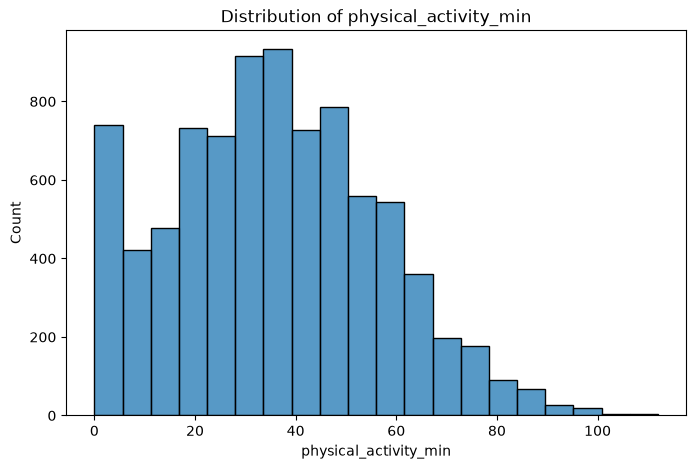

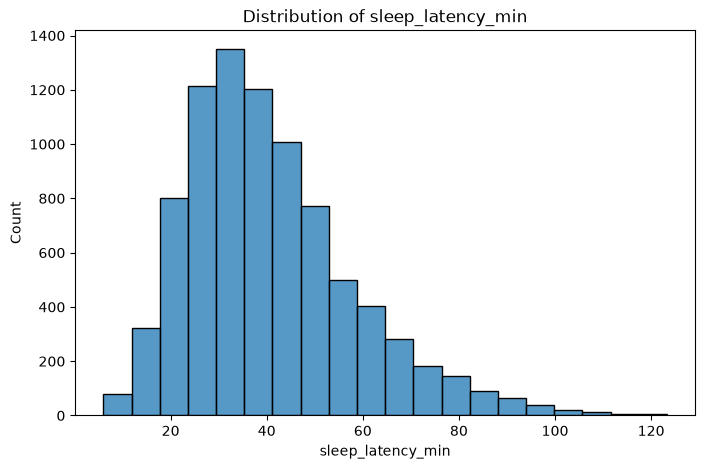

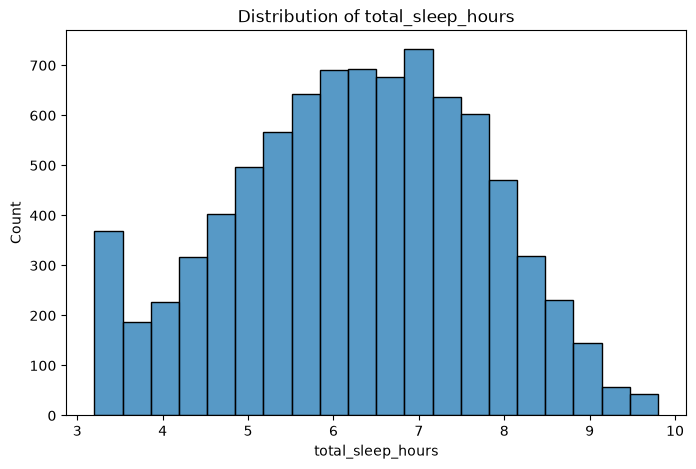

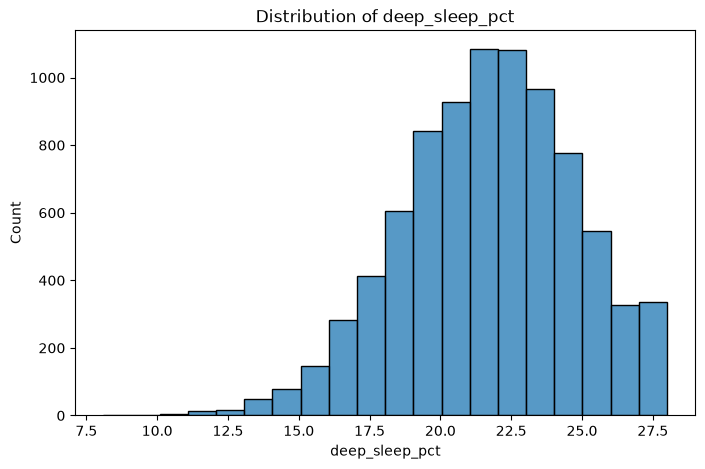

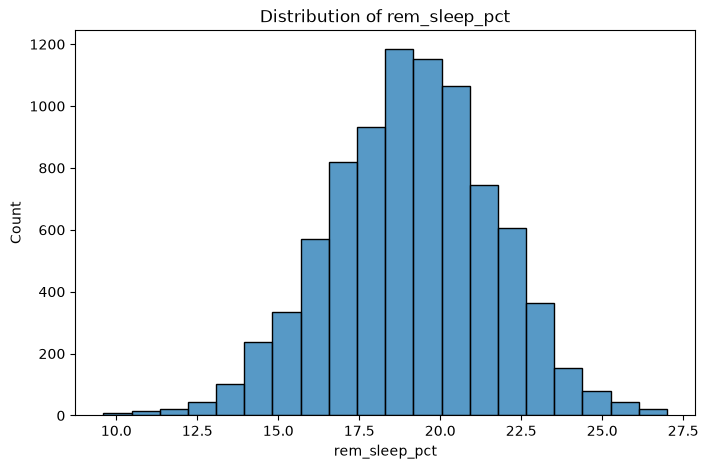

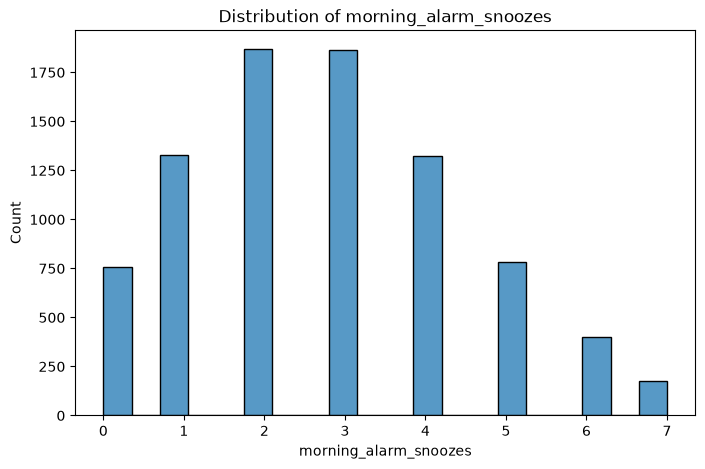

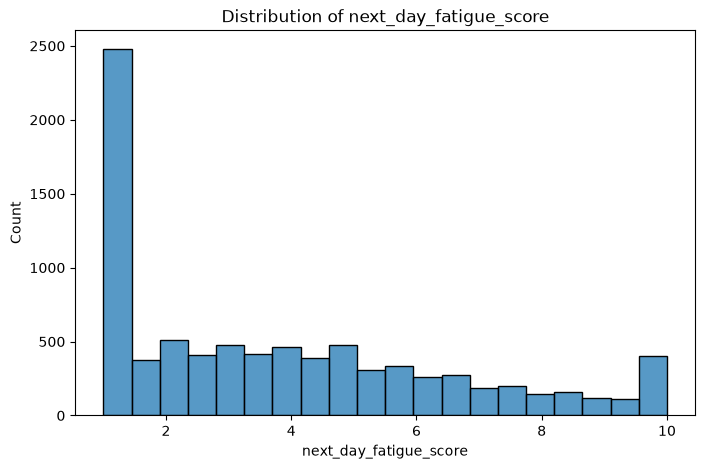

In [4]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).drop(columns=['blue_light_filter_active'], errors='ignore')
for col in numerical_cols:

    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, bins=20)
    plt.title(f'Distribution of {col}')
    plt.show()

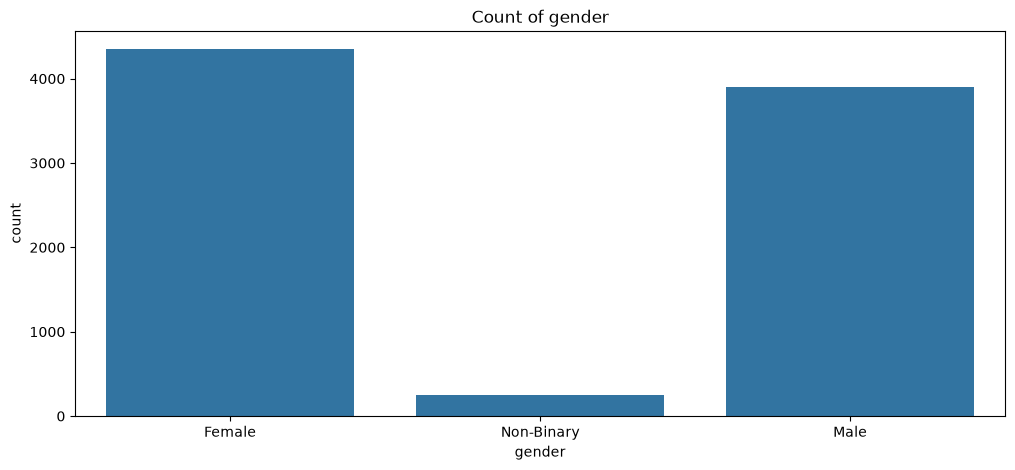

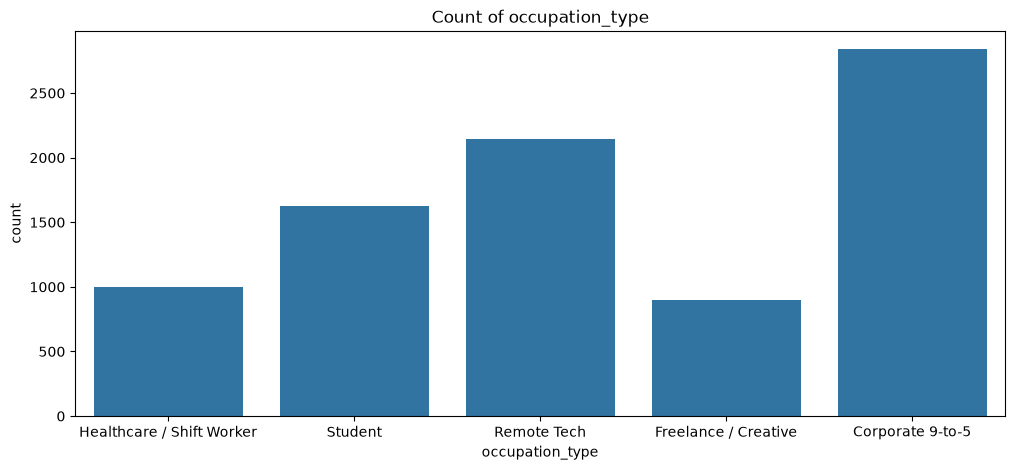

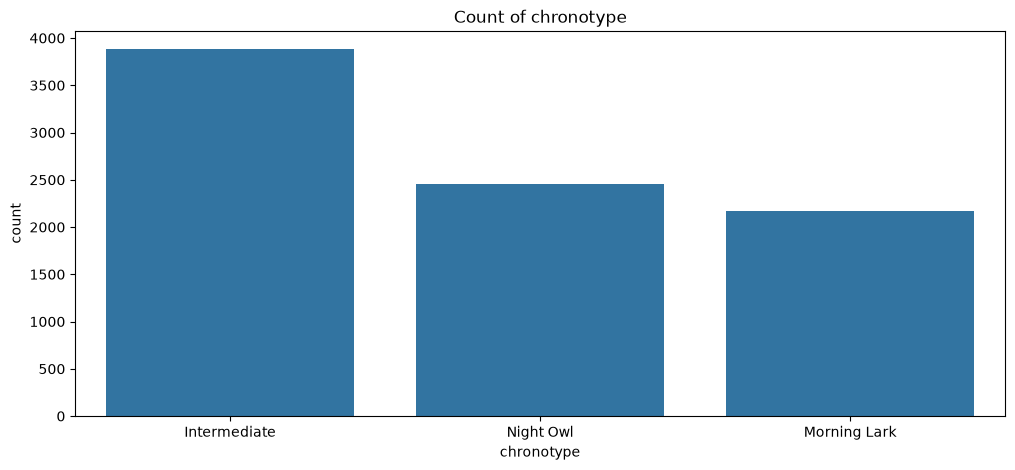

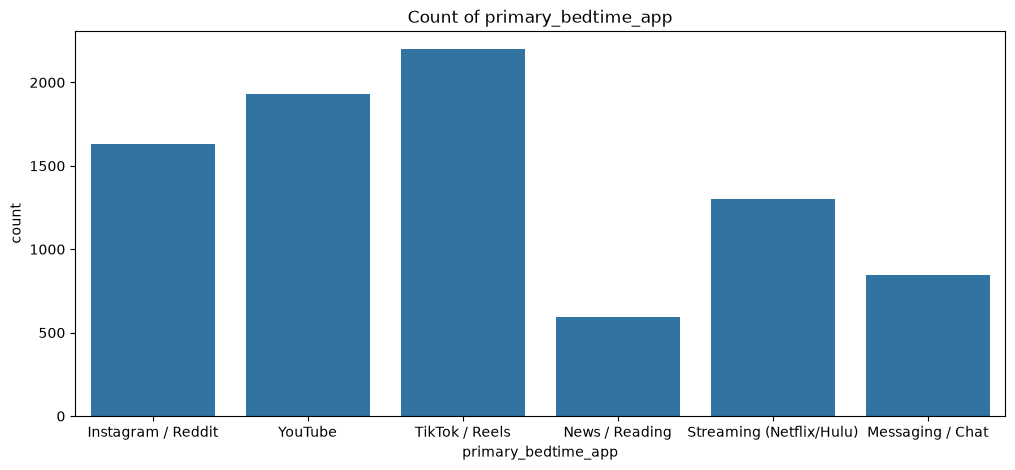

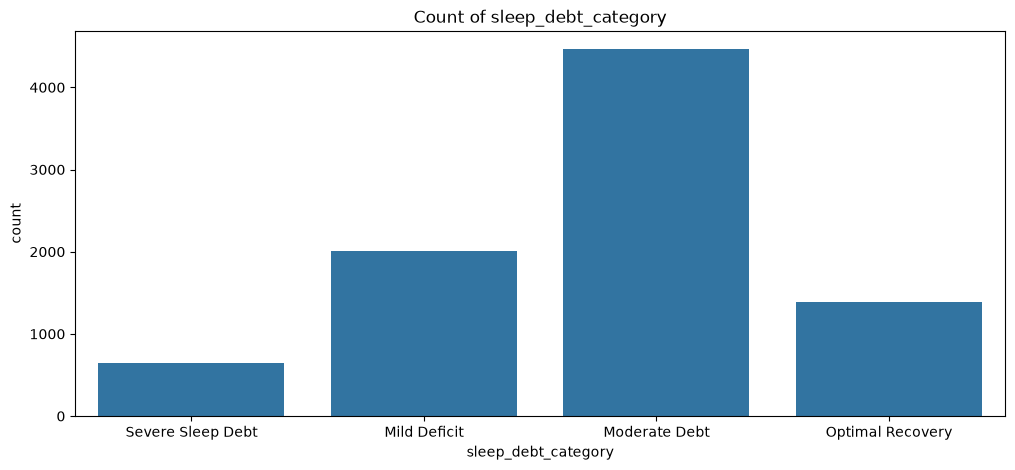

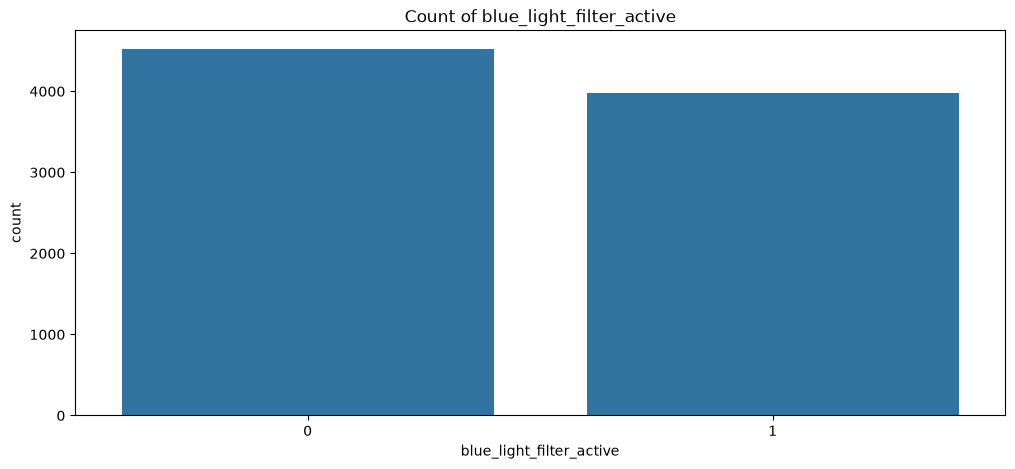

In [5]:
categorical_cols = df.select_dtypes(include=['str', 'category', 'bool']).columns.drop('user_id').to_list()

categorical_cols.append('blue_light_filter_active')

for col in categorical_cols:

    plt.figure(figsize=(12, 5))
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.show()

In [6]:
df['sleep_debt_category'].value_counts()

sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

In [7]:
df['sleep_debt_category'].value_counts(normalize=True) * 100

sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64

Το dataset παρουσιάζει πρόβλημα μη ισορροπημένων κλάσεων (class imbalance), καθώς οι παρατηρήσεις δεν κατανέμονται ομοιόμορφα μεταξύ των τεσσάρων κατηγοριών της μεταβλητής στόχου sleep_debt_category.

Συγκεκριμένα, η κλάση Moderate Debt συγκεντρώνει το 52,49% των παρατηρήσεων, ενώ η Severe Sleep Debt μόλις το 7,61%. Επομένως, ένα μοντέλο ταξινόμησης ενδέχεται να ευνοεί την πλειοψηφική κλάση και να παρουσιάζει χαμηλότερη απόδοση στις μειοψηφικές κλάσεις.

# Αφαίρεση μεταβλητής next_day_fatigue_score

In [8]:
df = df.drop(columns=['next_day_fatigue_score'])

# Επαλήθευση ότι αφαιρέθηκε

In [9]:
df.columns

Index(['user_id', 'age', 'gender', 'occupation_type', 'chronotype',
       'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'sleep_debt_category'],
      dtype='str')

# Εφαρμογή One-Hot Encoding στις κατηγορικές μεταβλητές

In [10]:
categorical_cols = df.select_dtypes(
    include=['object', 'str', 'category']
).columns.drop(['user_id', 'sleep_debt_category'], errors='ignore').to_list()

categorical_cols.append('blue_light_filter_active')

df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

df.head()

,user_id,age,bedtime_phone_minutes,screen_brightness_pct,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube,blue_light_filter_active_0,blue_light_filter_active_1
0,USR-00001,29,179,54,0,21,84.4,3.20,23.5,22.2,...,0,0,1,0,0,0,0,0,0,1
1,USR-00002,58,163,76,92,72,86.7,4.06,18.0,21.5,...,0,0,0,0,0,0,0,1,0,1
2,USR-00003,41,100,59,45,23,70.5,3.20,18.1,20.5,...,0,1,0,0,0,0,1,0,1,0
3,USR-00004,36,34,52,97,49,38.1,6.99,21.6,22.4,...,0,0,0,0,0,0,0,1,1,0
4,USR-00005,23,27,82,0,38,32.3,4.58,24.1,22.8,...,0,0,0,0,0,0,1,0,0,1


# Μετατροπή δεδομένων σε Arrays (x, y)

In [11]:
X = df.drop(columns=['sleep_debt_category', 'user_id']).to_numpy()
y = df['sleep_debt_category'].to_numpy()

# Χωρισμός dataset σε train-validation-test με ποσοστά 70-20-10 με seed=0 και με επιλογή stratify

In [12]:
# 1ος διαχωρισμός: 70% train - 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=0,
    stratify=y
)

# 2ος διαχωρισμός: 20% validation - 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=1/3,
    random_state=0,
    stratify=y_temp
)

# Έλεγχος διαστάσεων
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (5950, 29) (5950,)
Validation: (1700, 29) (1700,)
Test: (850, 29) (850,)


# Κανονικοποίηση δεδομένων

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

Χρησιμοποιούμε fit_transform μόνο στο train και transform στο validation, ώστε να αποφύγουμε τη διαρροή πληροφοριών (data leakage).

# Εκπαίδευση και αξιολόγηση KNN

In [14]:
# Τιμές παραμέτρων
k_values = [3, 5, 15, 50, int(np.sqrt(len(X_train)))]
weights_values = ['uniform', 'distance']

results = []

for k in k_values:
    for weight in weights_values:

        # Εκπαίδευση KNN
        knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
        knn.fit(X_train_scaled, y_train)

        # Προβλέψεις
        y_train_pred = knn.predict(X_train_scaled)
        y_val_pred = knn.predict(X_val_scaled)

        # Υπολογισμός μετρικών
        for dataset, y_true, y_pred in [
            ('Train', y_train, y_train_pred),
            ('Validation', y_val, y_val_pred)
        ]:
            results.append({
                'k': k,
                'weights': weight,
                'Dataset': dataset,
                'Accuracy': accuracy_score(y_true, y_pred),
                'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
                'Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
                'F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
                'Balanced Acc': balanced_accuracy_score(y_true, y_pred)
            })

# Πίνακας αποτελεσμάτων
results_df = pd.DataFrame(results)

display(results_df.round(3))

,k,weights,Dataset,Accuracy,Precision,Recall,F1,Balanced Acc
0,3,uniform,Train,0.846,0.856,0.788,0.815,0.788
1,3,uniform,Validation,0.688,0.676,0.601,0.628,0.601
2,3,distance,Train,1.000,1.000,1.000,1.000,1.000
3,3,distance,Validation,0.686,0.668,0.599,0.624,0.599
4,5,uniform,Train,0.806,0.831,0.727,0.764,0.727
5,5,uniform,Validation,0.705,0.714,0.607,0.640,0.607
6,5,distance,Train,1.000,1.000,1.000,1.000,1.000
7,5,distance,Validation,0.700,0.698,0.605,0.635,0.605
8,15,uniform,Train,0.762,0.800,0.641,0.682,0.641
9,15,uniform,Validation,0.715,0.751,0.579,0.619,0.579


# Εύρεση καλύτερου συνδυασμού

Επειδή έχουμε μη ισορροπημένες κλάσεις, επιλέγουμε το καλύτερο μοντέλο βάσει του Balanced Accuracy στο validation.

In [15]:
val_results = results_df[results_df['Dataset'] == 'Validation']

best_model = val_results.sort_values(
    by='Balanced Acc', ascending=False
).iloc[0]

print("Best k:", best_model['k'])
print("Best weights:", best_model['weights'])
print("Best Balanced Accuracy:", round(best_model['Balanced Acc'], 3))

Best k: 5
Best weights: uniform
Best Balanced Accuracy: 0.607


# Ένωση train-validation και κανονικοποίηση

In [16]:
# Ένωση train και validation
X_train_val = np.concatenate((X_train, X_val), axis=0)
y_train_val = np.concatenate((y_train, y_val), axis=0)

# Ενημέρωση scaler
scaler = StandardScaler()

X_train_val_scaled = scaler.fit_transform(X_train_val)
X_test_scaled = scaler.transform(X_test)

# Εκπαίδευση του καλύτερου KNN

In [17]:
# Καλύτερες παράμετροι 
best_k = int(best_model['k'])
best_weight = best_model['weights']

# Εκπαίδευση τελικού KNN
knn_final = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weight
)

knn_final.fit(X_train_val_scaled, y_train_val)

# Προβλέψεις
y_train_val_pred = knn_final.predict(X_train_val_scaled)
y_test_pred = knn_final.predict(X_test_scaled)

# Υπολογισμός μετρικών και συγκριτικός πίνακας

In [18]:
# Μετρικές τελικού μοντέλου
final_results = []

for dataset, y_true, y_pred in [
    ('Train-Validation', y_train_val, y_train_val_pred),
    ('Test', y_test, y_test_pred)
]:
    final_results.append({
        'Dataset': dataset,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_true, y_pred)
    })

final_df = pd.DataFrame(final_results)

# Αποτελέσματα του καλύτερου συνδυασμού από το ερώτημα 5
previous_results = results_df[
    (results_df['k'] == best_k) &
    (results_df['weights'] == best_weight)
].drop(columns=['k', 'weights'])

# Συγκριτικός πίνακας
comparison_df = pd.concat(
    [previous_results, final_df],
    ignore_index=True
)

display(comparison_df.round(3))

,Dataset,Accuracy,Precision,Recall,F1,Balanced Acc
0,Train,0.806,0.831,0.727,0.764,0.727
1,Validation,0.705,0.714,0.607,0.640,0.607
2,Train-Validation,0.807,0.831,0.730,0.766,0.730
3,Test,0.724,0.756,0.637,0.677,0.637


Ο καλύτερος συνδυασμός παραμέτρων ήταν k=5 και weights='uniform', με Balanced Accuracy 0,607 στο validation set.

Η Balanced Accuracy μειώθηκε από 0,727 στο train σε 0,607 στο validation, γεγονός που υποδηλώνει πιθανή υπερπροσαρμογή (overfitting). Ωστόσο, η επίδοση στο test (0,637) ήταν κοντά σε εκείνη του validation, δείχνοντας σχετικά σταθερή συμπεριφορά σε νέα δεδομένα.

Επιπλέον, η χαμηλότερη Balanced Accuracy σε σχέση με την Accuracy υποδηλώνει ότι το μοντέλο δεν παρουσιάζει εξίσου καλή απόδοση σε όλες τις κλάσεις.

# Διαχωρισμός Train-Test

In [19]:
# Train 90% - Test 10%
X_train_cv, X_test_cv, y_train_cv, y_test_cv = train_test_split(
    X, y,
    test_size=0.10,
    random_state=0,
    stratify=y
)

print("Train:", X_train_cv.shape)
print("Test:", X_test_cv.shape)

Train: (7650, 29)
Test: (850, 29)


# Ορισμός 5-Fold Cross Validation

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Παράμετροι KNN
k_values = [3, 5, 15, 50, int(np.sqrt(len(X_train_cv)))]
weights_values = ['uniform', 'distance']

# Μετρικές αξιολόγησης
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision_macro',
    'Recall': 'recall_macro',
    'F1': 'f1_macro',
    'Balanced Acc': 'balanced_accuracy'
}

# Εκπαίδευση και αξιολόγηση KNN

In [21]:
results_cv = []
fold_results = {}

for k in k_values:
    for weight in weights_values:

        # Scaler + KNN
        model = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(
                n_neighbors=k,
                weights=weight
            )
        )

        # 5-Fold Cross Validation
        scores = cross_validate(
            model,
            X_train_cv,
            y_train_cv,
            cv=cv,
            scoring=scoring
        )

        # Αποθήκευση αποτελεσμάτων των 5 folds
        fold_results[(k, weight)] = scores

        # Μέσος όρος μετρικών
        results_cv.append({
            'k': k,
            'weights': weight,
            'Accuracy': scores['test_Accuracy'].mean(),
            'Precision': scores['test_Precision'].mean(),
            'Recall': scores['test_Recall'].mean(),
            'F1': scores['test_F1'].mean(),
            'Balanced Acc': scores['test_Balanced Acc'].mean()
        })

# Πίνακας αποτελεσμάτων
results_cv_df = pd.DataFrame(results_cv)

display(results_cv_df.round(3))

,k,weights,Accuracy,Precision,Recall,F1,Balanced Acc
0,3,uniform,0.693,0.690,0.604,0.632,0.604
1,3,distance,0.691,0.674,0.601,0.626,0.601
2,5,uniform,0.701,0.713,0.597,0.631,0.597
3,5,distance,0.699,0.699,0.596,0.628,0.596
4,15,uniform,0.714,0.752,0.586,0.625,0.586
5,15,distance,0.718,0.751,0.594,0.633,0.594
6,50,uniform,0.728,0.774,0.567,0.603,0.567
7,50,distance,0.731,0.773,0.577,0.614,0.577
8,87,uniform,0.724,0.772,0.551,0.582,0.551
9,87,distance,0.726,0.772,0.556,0.588,0.556


# Εύρεση καλύτερου συνδυασμού

In [22]:
best_cv = results_cv_df.sort_values(
    by='Balanced Acc',
    ascending=False
).iloc[0]

best_k_cv = int(best_cv['k'])
best_weight_cv = best_cv['weights']

print("Best k:", best_k_cv)
print("Best weights:", best_weight_cv)
print("Best Balanced Accuracy:", round(best_cv['Balanced Acc'], 3))

Best k: 3
Best weights: uniform
Best Balanced Accuracy: 0.604


# Υπολογισμός διαστήματος εμπιστοσύνης 95% 

In [23]:
# Scores καλύτερου μοντέλου
best_scores = fold_results[(best_k_cv, best_weight_cv)]

ci_results = []

for metric in scoring.keys():

    values = best_scores['test_' + metric]

    mean = np.mean(values)
    std = np.std(values, ddof=1)

    # 95% Confidence Interval
    margin = t.ppf(0.975, df=4) * std / np.sqrt(5)

    ci_results.append({
        'Metric': metric,
        'Mean': mean,
        'CI Lower': mean - margin,
        'CI Upper': mean + margin
    })

ci_df = pd.DataFrame(ci_results)

display(ci_df.round(3))

,Metric,Mean,CI Lower,CI Upper
0,Accuracy,0.693,0.675,0.712
1,Precision,0.690,0.680,0.700
2,Recall,0.604,0.573,0.634
3,F1,0.632,0.606,0.658
4,Balanced Acc,0.604,0.573,0.634


Για τον καλύτερο συνδυασμό παραμέτρων του 5-Fold CV, η μέση Balanced Accuracy ήταν 0,604, με προσεγγιστικό διάστημα εμπιστοσύνης 95% από 0,573 έως 0,634.

Η μέση Accuracy ήταν 0,693, με αντίστοιχο διάστημα από 0,675 έως 0,712.

Τα διαστήματα υπολογίστηκαν με βάση τις επιδόσεις στα πέντε folds και την κατανομή Student's t. Αποτελούν προσεγγιστικές εκτιμήσεις, καθώς τα σύνολα εκπαίδευσης των folds αλληλεπικαλύπτονται.

# Τελική αξιολόγηση στο Test Set

In [24]:
# Τελικό μοντέλο
knn_cv_final = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=best_k_cv,
        weights=best_weight_cv
    )
)

knn_cv_final.fit(X_train_cv, y_train_cv)

# Προβλέψεις test
y_test_cv_pred = knn_cv_final.predict(X_test_cv)

# Αξιολόγηση
test_cv_results = {
    'Accuracy': accuracy_score(y_test_cv, y_test_cv_pred),
    'Precision': precision_score(y_test_cv, y_test_cv_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test_cv, y_test_cv_pred, average='macro', zero_division=0),
    'F1': f1_score(y_test_cv, y_test_cv_pred, average='macro', zero_division=0),
    'Balanced Acc': balanced_accuracy_score(y_test_cv, y_test_cv_pred)
}

display(pd.DataFrame([test_cv_results]).round(3))

,Accuracy,Precision,Recall,F1,Balanced Acc
0,0.7,0.7,0.623,0.651,0.623


Εφαρμόστηκε 5-Fold Stratified Cross Validation στο 90% των δεδομένων για την επιλογή των βέλτιστων παραμέτρων του ταξινομητή KNN. Για κάθε συνδυασμό παραμέτρων υπολογίστηκε ο μέσος όρος των πέντε μετρικών αξιολόγησης στα folds.

Ο καλύτερος συνδυασμός επιλέχθηκε με βάση τη μεγαλύτερη μέση Balanced Accuracy, λόγω της ανισορροπίας των κλάσεων. Για τον συγκεκριμένο συνδυασμό υπολογίστηκαν προσεγγιστικά διαστήματα εμπιστοσύνης 95% με βάση τις επιδόσεις στα πέντε folds, ώστε να εξεταστεί η μεταβλητότητα των αποτελεσμάτων.

Τέλος, το μοντέλο εκπαιδεύτηκε σε ολόκληρο το train set και αξιολογήθηκε στο ανεξάρτητο test set.

# Nested 5-Fold CV με 3 outer folds

In [25]:
# Outer και Inner CV
outer_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=0
)

inner_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=0
)

# Pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Παράμετροι KNN
k_values = [3, 5, 15, 50, int(np.sqrt(len(X_train_cv)))]

param_grid = {
    'knn__n_neighbors': k_values,
    'knn__weights': ['uniform', 'distance']
}

# Grid Search στο inner loop
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=inner_cv,
    scoring='balanced_accuracy',
    refit=True
)

# Εκτέλεση Nested CV και υπολογισμός μετρικών

In [26]:
nested_results = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train_cv, y_train_cv), start=1
):

    # Δεδομένα outer fold
    X_outer_train = X_train_cv[train_idx]
    X_outer_val = X_train_cv[val_idx]

    y_outer_train = y_train_cv[train_idx]
    y_outer_val = y_train_cv[val_idx]

    # Inner 5-Fold CV για επιλογή παραμέτρων
    grid_search.fit(X_outer_train, y_outer_train)

    # Καλύτερο μοντέλο
    best_knn = grid_search.best_estimator_

    # Προβλέψεις στο outer validation
    y_pred = best_knn.predict(X_outer_val)

    # Αποθήκευση αποτελεσμάτων
    nested_results.append({
        'Fold': fold,
        'Best k': grid_search.best_params_['knn__n_neighbors'],
        'Best weights': grid_search.best_params_['knn__weights'],
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_outer_val, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_outer_val, y_pred, average='macro', zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_outer_val, y_pred)
    })

nested_df = pd.DataFrame(nested_results)

display(nested_df.round(3))

,Fold,Best k,Best weights,Accuracy,Precision,Recall,F1,Balanced Acc
0,1,5,uniform,0.690,0.711,0.578,0.612,0.578
1,2,3,uniform,0.690,0.699,0.601,0.633,0.601
2,3,5,distance,0.697,0.695,0.591,0.624,0.591


# Μέσος όρος μετρικών

In [27]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Acc']

nested_mean = nested_df[metrics].mean()

print("Nested CV - Mean Scores:")
print(nested_mean.round(3))

Nested CV - Mean Scores:
Accuracy        0.692
Precision       0.702
Recall          0.590
F1              0.623
Balanced Acc    0.590
dtype: float64


# Υπολογισμός διαστήματος εμπιστοσύνης 95% 

In [28]:
nested_ci_results = []

for metric in metrics:

    values = nested_df[metric]

    mean = values.mean()
    std = values.std(ddof=1)

    margin = t.ppf(0.975, df=2) * std / np.sqrt(3)

    nested_ci_results.append({
        'Metric': metric,
        'Mean': mean,
        'CI Lower': mean - margin,
        'CI Upper': mean + margin
    })

nested_ci_df = pd.DataFrame(nested_ci_results)

display(nested_ci_df.round(3))

,Metric,Mean,CI Lower,CI Upper
0,Accuracy,0.692,0.682,0.703
1,Precision,0.702,0.681,0.722
2,Recall,0.590,0.562,0.618
3,F1,0.623,0.597,0.649
4,Balanced Acc,0.590,0.562,0.618


# Σύγκριση 5-Fold CV και Nested CV

In [29]:
comparison_cv = pd.DataFrame({
    'Metric': metrics,
    '5-Fold CV': [best_cv[m] for m in metrics],
    'Nested CV': [nested_mean[m] for m in metrics]
})

display(comparison_cv.round(3))

,Metric,5-Fold CV,Nested CV
0,Accuracy,0.693,0.692
1,Precision,0.690,0.702
2,Recall,0.604,0.590
3,F1,0.632,0.623
4,Balanced Acc,0.604,0.590


Η σύγκριση μεταξύ 5-Fold CV και Nested CV δείχνει παρόμοιες επιδόσεις. Συγκεκριμένα, η Balanced Accuracy μειώθηκε ελαφρώς από 0,604 σε 0,590, ενώ η Accuracy παρέμεινε σχεδόν αμετάβλητη.

Η μικρή αυτή διαφορά είναι συμβατή με το γεγονός ότι το Nested CV πραγματοποιεί ανεξάρτητη αξιολόγηση της διαδικασίας επιλογής υπερπαραμέτρων, περιορίζοντας την αισιόδοξη μεροληψία του απλού Cross Validation.

Συνεπώς, οι δύο διαδικασίες δίνουν συγκρίσιμη εικόνα για την αναμενόμενη απόδοση του ταξινομητή.

# Τελική αξιολόγηση στο Test

In [30]:
# Εύρεση καλύτερων παραμέτρων στο συνολικό train
grid_search.fit(X_train_cv, y_train_cv)

final_nested_model = grid_search.best_estimator_

# Πρόβλεψη στο test
y_test_nested_pred = final_nested_model.predict(X_test_cv)

test_nested_results = {
    'Accuracy': accuracy_score(y_test_cv, y_test_nested_pred),
    'Precision': precision_score(y_test_cv, y_test_nested_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test_cv, y_test_nested_pred, average='macro', zero_division=0),
    'F1': f1_score(y_test_cv, y_test_nested_pred, average='macro', zero_division=0),
    'Balanced Acc': balanced_accuracy_score(y_test_cv, y_test_nested_pred)
}

print("Best parameters:", grid_search.best_params_)

display(pd.DataFrame([test_nested_results]).round(3))

Best parameters: {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


,Accuracy,Precision,Recall,F1,Balanced Acc
0,0.7,0.7,0.623,0.651,0.623


Εφαρμόστηκε Nested Cross Validation με 3 outer folds και 5 inner folds. Στο inner loop πραγματοποιήθηκε αναζήτηση του καλύτερου συνδυασμού παραμέτρων του KNN με βάση τη Balanced Accuracy, ενώ στο outer loop αξιολογήθηκε η απόδοση του επιλεγμένου μοντέλου.

Οι τελικές μετρικές του Nested CV υπολογίστηκαν ως ο μέσος όρος των αποτελεσμάτων στα 3 outer folds. Σε αντίθεση με το απλό Cross Validation, το Nested CV διαχωρίζει τη διαδικασία επιλογής παραμέτρων από την αξιολόγηση, περιορίζοντας την αισιόδοξη μεροληψία που μπορεί να προκύψει από τη βελτιστοποίηση των παραμέτρων.

# Μέρος 2

# Προετοιμασία δεδομένων

In [31]:
# Φόρτωση δεδομένων
df_reg = pd.read_csv('sleep.csv')

# Αφαίρεση προηγούμενης μεταβλητής στόχου
df_reg = df_reg.drop(columns=['sleep_debt_category', 'user_id'])

# One-Hot Encoding
categorical_cols = df_reg.select_dtypes(
    include=['object', 'str', 'category']
).columns.to_list()

categorical_cols.append('blue_light_filter_active')

df_reg = pd.get_dummies(
    df_reg,
    columns=categorical_cols,
    dtype=int
)

# Μετατροπή σε arrays
X_reg = df_reg.drop(columns=['next_day_fatigue_score']).to_numpy()
y_reg = df_reg['next_day_fatigue_score'].to_numpy()

# Έλεγχος κατανομής με διάγραμμα

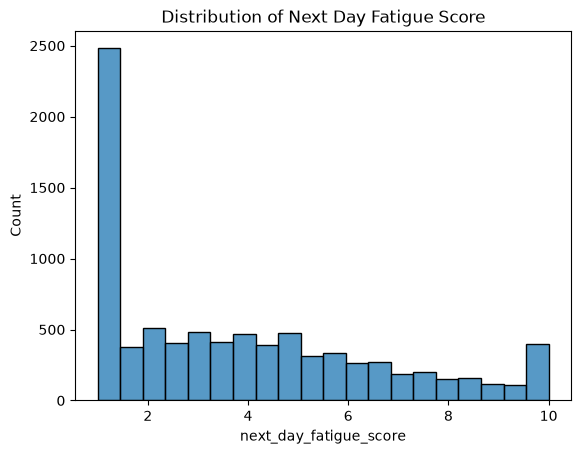

In [32]:
sns.histplot(data=df_reg, x='next_day_fatigue_score', bins=20)
plt.title('Distribution of Next Day Fatigue Score')
plt.show()

# Train – Validation – Test (70%-20%-10%)

In [33]:
X_train_reg, X_temp_reg, y_train_reg, y_temp_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.30,
    random_state=0
)

X_val_reg, X_test_reg, y_val_reg, y_test_reg = train_test_split(
    X_temp_reg, y_temp_reg,
    test_size=1/3,
    random_state=0
)

# Z-Normalization
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_val_reg_scaled = scaler_reg.transform(X_val_reg)

# Εκπαίδευση KNN Regressor και επιλογή παραμέτρων

In [34]:
# Παράμετροι
k_values_reg = [3, 5, 15, 50, int(np.sqrt(len(X_train_reg)))]
weights_values = ['uniform', 'distance']

results_reg = []

for k in k_values_reg:
    for weight in weights_values:

        knn = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        knn.fit(X_train_reg_scaled, y_train_reg)

        y_train_pred = knn.predict(X_train_reg_scaled)
        y_val_pred = knn.predict(X_val_reg_scaled)

        for dataset, y_true, y_pred in [
            ('Train', y_train_reg, y_train_pred),
            ('Validation', y_val_reg, y_val_pred)
        ]:
            results_reg.append({
                'k': k,
                'weights': weight,
                'Dataset': dataset,
                'MAE': mean_absolute_error(y_true, y_pred),
                'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))
            })

results_reg_df = pd.DataFrame(results_reg)

display(results_reg_df.round(3))

,k,weights,Dataset,MAE,RMSE
0,3,uniform,Train,0.657,0.897
1,3,uniform,Validation,0.922,1.257
2,3,distance,Train,0.000,0.000
3,3,distance,Validation,0.910,1.244
4,5,uniform,Train,0.742,0.986
5,5,uniform,Validation,0.884,1.178
6,5,distance,Train,0.000,0.000
7,5,distance,Validation,0.871,1.164
8,15,uniform,Train,0.857,1.088
9,15,uniform,Validation,0.918,1.160


# Επιλογή καλύτερου συνδυασμού

In [35]:
val_results_reg = results_reg_df[
    results_reg_df['Dataset'] == 'Validation'
]

best_reg = val_results_reg.sort_values(
    by='RMSE'
).iloc[0]

best_k_reg = int(best_reg['k'])
best_weight_reg = best_reg['weights']

print("Best k:", best_k_reg)
print("Best weights:", best_weight_reg)
print("Best RMSE:", round(best_reg['RMSE'], 3))

Best k: 15
Best weights: distance
Best RMSE: 1.141


# Ένωση Train-Validation και αξιολόγηση στο Test

In [36]:
# Ένωση δεδομένων
X_train_val_reg = np.concatenate(
    (X_train_reg, X_val_reg), axis=0
)

y_train_val_reg = np.concatenate(
    (y_train_reg, y_val_reg), axis=0
)

# Ενημέρωση scaler
scaler_reg = StandardScaler()

X_train_val_scaled = scaler_reg.fit_transform(X_train_val_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Εκπαίδευση τελικού μοντέλου
knn_reg_final = KNeighborsRegressor(
    n_neighbors=best_k_reg,
    weights=best_weight_reg
)

knn_reg_final.fit(X_train_val_scaled, y_train_val_reg)

# Προβλέψεις
y_train_val_pred = knn_reg_final.predict(X_train_val_scaled)
y_test_pred = knn_reg_final.predict(X_test_reg_scaled)

# Αποτελέσματα
final_reg_results = []

for dataset, y_true, y_pred in [
    ('Train-Validation', y_train_val_reg, y_train_val_pred),
    ('Test', y_test_reg, y_test_pred)
]:
    final_reg_results.append({
        'Dataset': dataset,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))
    })

final_reg_df = pd.DataFrame(final_reg_results)

previous_reg = results_reg_df[
    (results_reg_df['k'] == best_k_reg) &
    (results_reg_df['weights'] == best_weight_reg)
].drop(columns=['k', 'weights'])

comparison_reg = pd.concat(
    [previous_reg, final_reg_df],
    ignore_index=True
)

display(comparison_reg.round(3))

,Dataset,MAE,RMSE
0,Train,0.000,0.000
1,Validation,0.901,1.141
2,Train-Validation,0.000,0.000
3,Test,0.876,1.137


Ο καλύτερος συνδυασμός παραμέτρων ήταν k=15 και weights='distance', με RMSE 1,141 στο validation set.

Παρατηρείται μηδενικό σφάλμα στο train, το οποίο οφείλεται στη λειτουργία του KNN με στάθμιση βάσει απόστασης. Ωστόσο, η επίδοση αυτή δεν αντανακλά απαραίτητα την ικανότητα γενίκευσης του μοντέλου.

Στο test set προέκυψαν MAE 0,876 και RMSE 1,137, τιμές πολύ κοντά στις αντίστοιχες του validation (0,901 και 1,141). Το αποτέλεσμα αυτό αποτελεί θετική ένδειξη σχετικά με τη σταθερότητα των προβλέψεων σε νέα δεδομένα.

# 5-Fold Cross Validation

Χρησιμοποιούμε 90% train και 10% test. Για το CV εφαρμόζουμε KFold αντί για StratifiedKFold, επειδή πρόκειται για παλινδρόμηση.

In [37]:
# Train-Test 90%-10%
X_train_cv_reg, X_test_cv_reg, y_train_cv_reg, y_test_cv_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.10,
    random_state=0
)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=0)

k_values_cv = [3, 5, 15, 50, int(np.sqrt(len(X_train_cv_reg)))]

scoring_reg = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error'
}

results_cv_reg = []
fold_results_reg = {}

for k in k_values_cv:
    for weight in weights_values:

        model = make_pipeline(
            StandardScaler(),
            KNeighborsRegressor(n_neighbors=k, weights=weight)
        )

        scores = cross_validate(
            model,
            X_train_cv_reg,
            y_train_cv_reg,
            cv=cv_reg,
            scoring=scoring_reg
        )

        fold_results_reg[(k, weight)] = scores

        results_cv_reg.append({
            'k': k,
            'weights': weight,
            'MAE': -scores['test_MAE'].mean(),
            'RMSE': -scores['test_RMSE'].mean()
        })

results_cv_reg_df = pd.DataFrame(results_cv_reg)

display(results_cv_reg_df.round(3))

,k,weights,MAE,RMSE
0,3,uniform,0.930,1.257
1,3,distance,0.919,1.243
2,5,uniform,0.913,1.206
3,5,distance,0.899,1.189
4,15,uniform,0.913,1.162
5,15,distance,0.899,1.146
6,50,uniform,0.949,1.184
7,50,distance,0.937,1.170
8,87,uniform,0.986,1.225
9,87,distance,0.973,1.210


# Καλύτερες παράμετροι και διάστημα εμπιστοσύνης 95%

In [38]:
best_cv_reg = results_cv_reg_df.sort_values(
    by='RMSE'
).iloc[0]

best_k_cv_reg = int(best_cv_reg['k'])
best_weight_cv_reg = best_cv_reg['weights']

best_scores_reg = fold_results_reg[
    (best_k_cv_reg, best_weight_cv_reg)
]

ci_results_reg = []

for metric in ['MAE', 'RMSE']:

    values = -best_scores_reg['test_' + metric]

    mean = values.mean()
    std = values.std(ddof=1)

    margin = t.ppf(0.975, df=4) * std / np.sqrt(5)

    ci_results_reg.append({
        'Metric': metric,
        'Mean': mean,
        'CI Lower': mean - margin,
        'CI Upper': mean + margin
    })

display(pd.DataFrame(ci_results_reg).round(3))

,Metric,Mean,CI Lower,CI Upper
0,MAE,0.899,0.870,0.927
1,RMSE,1.146,1.115,1.177


Για τον καλύτερο συνδυασμό παραμέτρων του 5-Fold CV, το μέσο MAE ήταν 0,899, με προσεγγιστικό διάστημα εμπιστοσύνης 95% από 0,870 έως 0,927.

Αντίστοιχα, το μέσο RMSE ήταν 1,146, με διάστημα από 1,115 έως 1,177.

Τα σχετικά μικρά εύρη των διαστημάτων δείχνουν περιορισμένη μεταβλητότητα μεταξύ των πέντε folds, χωρίς ωστόσο να εξασφαλίζουν την ίδια απόδοση σε νέα δεδομένα.

# Nested Cross Validation (3 Outer – 5 Inner Folds)

In [39]:
outer_cv_reg = KFold(n_splits=3, shuffle=True, random_state=0)
inner_cv_reg = KFold(n_splits=5, shuffle=True, random_state=0)

pipeline_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

param_grid_reg = {
    'knn__n_neighbors': k_values_cv,
    'knn__weights': ['uniform', 'distance']
}

grid_search_reg = GridSearchCV(
    pipeline_reg,
    param_grid_reg,
    cv=inner_cv_reg,
    scoring='neg_root_mean_squared_error',
    refit=True
)

nested_results_reg = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv_reg.split(X_train_cv_reg), start=1
):

    X_outer_train = X_train_cv_reg[train_idx]
    X_outer_val = X_train_cv_reg[val_idx]

    y_outer_train = y_train_cv_reg[train_idx]
    y_outer_val = y_train_cv_reg[val_idx]

    grid_search_reg.fit(X_outer_train, y_outer_train)

    best_knn_reg = grid_search_reg.best_estimator_

    y_pred = best_knn_reg.predict(X_outer_val)

    nested_results_reg.append({
        'Fold': fold,
        'Best k': grid_search_reg.best_params_['knn__n_neighbors'],
        'Best weights': grid_search_reg.best_params_['knn__weights'],
        'MAE': mean_absolute_error(y_outer_val, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_outer_val, y_pred))
    })

nested_reg_df = pd.DataFrame(nested_results_reg)

display(nested_reg_df.round(3))

# Μέσος όρος μετρικών
print("Nested CV Mean Scores:")
print(nested_reg_df[['MAE', 'RMSE']].mean().round(3))

,Fold,Best k,Best weights,MAE,RMSE
0,1,15,distance,0.891,1.131
1,2,15,distance,0.899,1.156
2,3,15,distance,0.913,1.158


Nested CV Mean Scores:
MAE     0.901
RMSE    1.148
dtype: float64


# Τελική αξιολόγηση στο test

In [40]:
grid_search_reg.fit(X_train_cv_reg, y_train_cv_reg)

final_model_reg = grid_search_reg.best_estimator_

y_test_cv_pred = final_model_reg.predict(X_test_cv_reg)

print("Best parameters:", grid_search_reg.best_params_)

print("Test MAE:", round(
    mean_absolute_error(y_test_cv_reg, y_test_cv_pred), 3
))

print("Test RMSE:", round(
    np.sqrt(mean_squared_error(y_test_cv_reg, y_test_cv_pred)), 3
))

Best parameters: {'knn__n_neighbors': 15, 'knn__weights': 'distance'}
Test MAE: 0.88
Test RMSE: 1.129


Τα αποτελέσματα του 5-Fold CV και του Nested CV παρουσιάζουν πολύ μικρές διαφορές. Συγκεκριμένα, το RMSE ήταν 1,146 και 1,148 αντίστοιχα, ενώ το MAE ήταν 0,899 και 0,901.

Η τελική αξιολόγηση στο test έδωσε MAE 0,880 και RMSE 1,129, επιβεβαιώνοντας ότι οι επιδόσεις βρίσκονται σε παρόμοια επίπεδα.

Επιπλέον, η επιλογή των παραμέτρων k=15 και weights='distance' ήταν σταθερή στις διαδικασίες αξιολόγησης, γεγονός που ενισχύει την εμπιστοσύνη στην επιλογή του συγκεκριμένου συνδυασμού.

# Συνολικά Συμπεράσματα

Στην εργασία εφαρμόστηκε ο αλγόριθμος KNN για την πρόβλεψη της κατηγορίας έλλειψης ύπνου και του επιπέδου κόπωσης της επόμενης ημέρας.

Στο πρόβλημα ταξινόμησης διαπιστώθηκε ανισορροπία μεταξύ των κλάσεων, με αποτέλεσμα η Balanced Accuracy να αποτελεί καταλληλότερο κριτήριο επιλογής παραμέτρων σε σχέση με την απλή Accuracy. Οι επιδόσεις έδειξαν ότι ο ταξινομητής παρουσιάζει περιορισμούς στην ισότιμη αναγνώριση όλων των κατηγοριών.

Στο πρόβλημα παλινδρόμησης, ο συνδυασμός k=15 και weights='distance' παρουσίασε παρόμοια αποτελέσματα μεταξύ validation, 5-Fold CV, Nested CV και test, με RMSE κοντά στο 1,1.

Συνολικά, η εφαρμογή Cross Validation και Nested Cross Validation επέτρεψε την πιο συστηματική αξιολόγηση των μοντέλων και τη διερεύνηση της σταθερότητας των επιδόσεων τους.